# Pendubot: from mechanics to DDP and iLQR

A self-contained, executable explanation of a two-link robot with one motor.
Every model and control function is defined here; no dashboard, local modules,
downloaded results, or external data are needed.

**Run:** select a Python environment with `requirements.txt` installed, then choose
**Kernel → Restart Kernel and Run All Cells**. The first run compiles JAX functions;
allow a few minutes. Saved outputs show a completed run and are replaced when rerun.

**Reading route:** coordinates → energy → equations of motion → state model → RK4
→ objective → local Hamiltonian → backward recursion → forward line search
→ DDP/iLQR comparison → feedback and upright LQR → animation.

The model uses uniform rigid rods, frictionless joints, exact state feedback,
and unconstrained motor torque. The terminal target is encouraged by a penalty.

## 1. Imports and numerical precision

NumPy handles reporting, Matplotlib draws results, and SciPy solves the upright
LQR Riccati equation. JAX differentiates the numerical dynamics and compiles the
repeated calculations. Double precision improves second derivatives and tight
convergence checks. `scan` runs a recurrence over the time grid.

In [1]:
from dataclasses import dataclass, replace, asdict
from functools import partial
import time
import platform

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import scipy
from scipy.linalg import solve_discrete_are
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Arc
from IPython.display import display, HTML, Markdown

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.2,
                     "axes.spines.top": False, "axes.spines.right": False})

def show_table(rows):
    keys = list(rows[0])
    def fmt(value):
        return f"{value:.6g}" if isinstance(value, (float, np.floating)) else str(value)
    lines = ["| " + " | ".join(keys) + " |", "| " + " | ".join(["---"]*len(keys)) + " |"]
    lines += ["| " + " | ".join(fmt(row[k]) for k in keys) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

print({"Python": platform.python_version(), "JAX": jax.__version__,
       "NumPy": np.__version__, "SciPy": scipy.__version__,
       "Matplotlib": matplotlib.__version__})

{'Python': '3.14.7', 'JAX': '0.12.0.1', 'NumPy': '2.5.4', 'SciPy': '1.18.1', 'Matplotlib': '3.11.2'}


## 2. Coordinates and parameters you can change

The base angle $q_1$ is measured from the **downward vertical**; positive rotation
follows the figure. The elbow angle $q_2$ is **relative to link 1**, so the second
link's absolute angle is $q_1+q_2$.

$$x=[q_1,q_2,v_1,v_2]^T,\quad v_i=\dot q_i,\qquad
x_0=[0,0,0,0]^T,\quad x_\star=[\pi,0,0,0]^T.$$

Only the base is driven: $\tau=[u,0]^T$. Coupling moves the passive elbow.
Lengths are metres, masses kilograms, time seconds, angles radians, and torque N·m.
For uniform rods, $l_{ci}=l_i/2$ and $I_i=m_i l_i^2/12$ about each centre of mass.

Edit the `Config` defaults below, or put `cfg = replace(cfg, m2=1.2)` immediately
after `cfg = Config()`. Then rerun from this cell onward. The model, costs, and
controller all receive `cfg` explicitly, preventing stale compiled settings.

In [2]:
@dataclass(frozen=True)
class Config:
    m1: float = 1.0
    m2: float = 1.0
    l1: float = 1.0
    l2: float = 1.0
    gravity: float = 9.81
    dt: float = 0.02
    duration: float = 6.0
    q: tuple = (1.0, 1.0, 0.1, 0.1)
    q_terminal: tuple = (2000.0, 2000.0, 200.0, 200.0)
    r: float = 0.01
    max_iterations: int = 1500
    relative_tolerance: float = 1e-8
    control_tolerance: float = 1e-3

    def __post_init__(self):
        if min(self.m1, self.m2, self.l1, self.l2, self.gravity, self.dt, self.duration, self.r) <= 0:
            raise ValueError("Masses, lengths, gravity, timing, and r must be positive.")
        if self.n < 1 or not np.isclose(self.n*self.dt, self.duration):
            raise ValueError("duration must be a positive integer multiple of dt.")
        if len(self.q) != 4 or len(self.q_terminal) != 4:
            raise ValueError("Each state-weight tuple must contain four numbers.")
        if min(self.q) < 0 or min(self.q_terminal) < 0 or self.max_iterations < 1:
            raise ValueError("Weights must be nonnegative and the iteration budget positive.")

    @property
    def n(self):
        return int(round(self.duration / self.dt))

cfg = Config()
# Example: cfg = replace(cfg, m2=1.2, duration=8.0)
X0 = jnp.zeros(4)
GOAL = jnp.array([jnp.pi, 0.0, 0.0, 0.0])
show_table([{"parameter": k, "value": v} for k, v in asdict(cfg).items()])
print("Control intervals:", cfg.n)

| parameter | value |
| --- | --- |
| m1 | 1 |
| m2 | 1 |
| l1 | 1 |
| l2 | 1 |
| gravity | 9.81 |
| dt | 0.02 |
| duration | 6 |
| q | (1.0, 1.0, 0.1, 0.1) |
| q_terminal | (2000.0, 2000.0, 200.0, 200.0) |
| r | 0.01 |
| max_iterations | 1500 |
| relative_tolerance | 1e-08 |
| control_tolerance | 0.001 |

Control intervals: 300


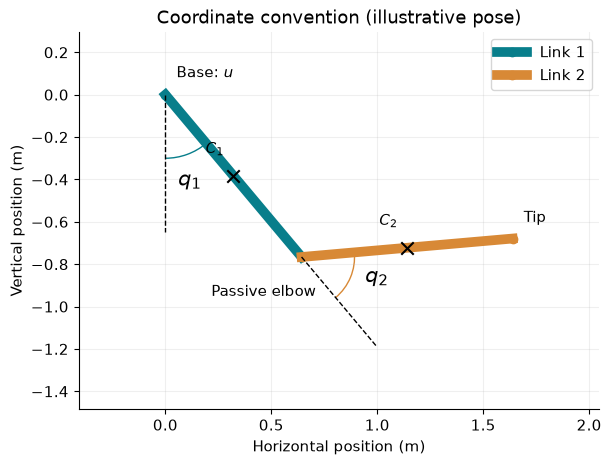

In [3]:
def joint_positions(x, cfg):
    q1, q2 = np.asarray(x)[:2]
    elbow = np.array([cfg.l1*np.sin(q1), -cfg.l1*np.cos(q1)])
    tip = elbow + np.array([cfg.l2*np.sin(q1+q2), -cfg.l2*np.cos(q1+q2)])
    return np.array([[0.0, 0.0], elbow, tip])

q_demo = np.deg2rad([40.0, 55.0])
p = joint_positions([*q_demo, 0, 0], cfg)
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.plot(p[:2, 0], p[:2, 1], "o-", lw=7, color="#087e8b", label="Link 1")
ax.plot(p[1:, 0], p[1:, 1], "o-", lw=7, color="#d88936", label="Link 2")
ax.plot([0, 0], [0, -0.65*cfg.l1], "k--", lw=1)
direction = np.array([np.sin(q_demo[0]), -np.cos(q_demo[0])])
extension = p[1] + 0.55*cfg.l2*direction
ax.plot([p[1, 0], extension[0]], [p[1, 1], extension[1]], "k--", lw=1)
ax.add_patch(Arc((0, 0), .6*cfg.l1, .6*cfg.l1, theta1=-90, theta2=-50, color="#087e8b"))
ax.add_patch(Arc(p[1], .5*cfg.l2, .5*cfg.l2, theta1=-50, theta2=5, color="#d88936"))
ax.text(.06*cfg.l1, -.43*cfg.l1, r"$q_1$", fontsize=15)
ax.text(*(p[1]+[.30*cfg.l2, -.12*cfg.l2]), r"$q_2$", fontsize=15)
for i, label in enumerate([r"Base: $u$", "Passive elbow", "Tip"]):
    offset = (-65, -28) if i == 1 else (8, 12)
    ax.annotate(label, p[i], xytext=offset, textcoords="offset points")
for i in range(2):
    com = (p[i]+p[i+1])/2
    ax.scatter(*com, marker="x", s=80, c="black", zorder=5)
    ax.annotate(fr"$C_{i+1}$", com, xytext=(-20, 16), textcoords="offset points")
ax.set(aspect="equal", xlabel="Horizontal position (m)", ylabel="Vertical position (m)",
       title="Coordinate convention (illustrative pose)")
ax.margins(.25)
ax.legend(loc="upper right")
plt.show()

## 3. Energy and the mechanical law

With $Y$ positive upward, the centre-of-mass positions are
$$p_{c1}=\begin{bmatrix}l_{c1}\sin q_1\\-l_{c1}\cos q_1\end{bmatrix},\quad
p_{c2}=\begin{bmatrix}l_1\sin q_1+l_{c2}\sin(q_1+q_2)\\
-l_1\cos q_1-l_{c2}\cos(q_1+q_2)\end{bmatrix}.$$
Differentiate them in time to obtain translational velocities. Add
$\tfrac12 m_i\|\dot p_{ci}\|^2$ and rotational energies
$\tfrac12 I_1v_1^2+\tfrac12 I_2(v_1+v_2)^2$. Define
$$\begin{aligned}
a&=I_1+m_1l_{c1}^2+m_2l_1^2+d,& b&=m_2l_1l_{c2},&d&=I_2+m_2l_{c2}^2,\\
\alpha&=(m_1l_{c1}+m_2l_1)g,&\beta&=m_2l_{c2}g.
\end{aligned}$$
The energies reduce to
$$\mathcal T=\tfrac12(a+2b\cos q_2)v_1^2+(d+b\cos q_2)v_1v_2+\tfrac12dv_2^2,$$
$$\mathcal V=-\alpha\cos q_1-\beta\cos(q_1+q_2),\qquad \mathcal L=\mathcal T-\mathcal V.$$

The definition of $\mathcal L$ does not by itself imply motion. Apply the
Euler–Lagrange mechanical law, including applied generalized torque:
$$\frac{d}{dt}\left(\frac{\partial\mathcal L}{\partial v_i}\right)
-\frac{\partial\mathcal L}{\partial q_i}=\tau_i,\quad i=1,2.$$
For these frictionless links, there are no additional dissipative torques.

In [4]:
def coefficients(cfg):
    lc1, lc2 = cfg.l1/2, cfg.l2/2
    I1, I2 = cfg.m1*cfg.l1**2/12, cfg.m2*cfg.l2**2/12
    d = I2 + cfg.m2*lc2**2
    a = I1 + cfg.m1*lc1**2 + cfg.m2*cfg.l1**2 + d
    b = cfg.m2*cfg.l1*lc2
    alpha = (cfg.m1*lc1 + cfg.m2*cfg.l1)*cfg.gravity
    beta = cfg.m2*lc2*cfg.gravity
    return a, b, d, alpha, beta

def mass_matrix(q, cfg):
    a, b, d, _, _ = coefficients(cfg)
    coupling = b*jnp.cos(q[1])
    return jnp.array([[a+2*coupling, d+coupling], [d+coupling, d]])

def kinetic_energy(x, cfg):
    return 0.5*x[2:] @ mass_matrix(x[:2], cfg) @ x[2:]

def potential_energy(x, cfg):
    _, _, _, alpha, beta = coefficients(cfg)
    return -alpha*jnp.cos(x[0]) - beta*jnp.cos(x[0]+x[1])

def energy(x, cfg):
    return kinetic_energy(x, cfg) + potential_energy(x, cfg)

show_table([dict(zip(["a", "b", "d", "alpha", "beta"], coefficients(cfg)))])

| a | b | d | alpha | beta |
| --- | --- | --- | --- | --- |
| 1.66667 | 0.5 | 0.333333 | 14.715 | 4.905 |

## 4. Equations of motion: where each term comes from

**Joint 1.** Differentiating the velocity derivative gives
$$\frac{d}{dt}\frac{\partial\mathcal L}{\partial v_1}
=(a+2b\cos q_2)\dot v_1+(d+b\cos q_2)\dot v_2
-2b\sin q_2\,v_1v_2-b\sin q_2\,v_2^2.$$
Also $\partial\mathcal L/\partial q_1=-\alpha\sin q_1-\beta\sin(q_1+q_2)$.
Substitution produces
$$M_{11}\ddot q_1+M_{12}\ddot q_2
-b\sin q_2(2v_1v_2+v_2^2)+\alpha\sin q_1+\beta\sin(q_1+q_2)=u.$$

**Joint 2.** Here
$$\frac{d}{dt}\frac{\partial\mathcal L}{\partial v_2}
=(d+b\cos q_2)\dot v_1+d\dot v_2-b\sin q_2\,v_1v_2,$$
$$\frac{\partial\mathcal L}{\partial q_2}
=-b\sin q_2(v_1^2+v_1v_2)-\beta\sin(q_1+q_2).$$
The $v_1v_2$ terms cancel after subtraction:
$$M_{12}\ddot q_1+M_{22}\ddot q_2+b\sin q_2\,v_1^2+\beta\sin(q_1+q_2)=0.$$

Collect the two equations:
$$\underbrace{\begin{bmatrix}a+2b\cos q_2&d+b\cos q_2\\d+b\cos q_2&d\end{bmatrix}}_{M(q)}\ddot q
+\underbrace{\begin{bmatrix}-b\sin q_2(2v_1v_2+v_2^2)\\b\sin q_2v_1^2\end{bmatrix}}_{c(q,v)}
+\underbrace{\begin{bmatrix}\alpha\sin q_1+\beta\sin(q_1+q_2)\\\beta\sin(q_1+q_2)\end{bmatrix}}_{G(q)}
=\begin{bmatrix}u\\0\end{bmatrix}.$$
$M$ describes inertia; $c$ contains velocity coupling; $G$ is gravity.
The zero elbow torque means the elbow has no motor, while $M_{12}$ couples its acceleration to the base.

## 5. Construct the continuous-time state model

Let $r=[u,0]^T-c-G$ and $\Delta=M_{11}M_{22}-M_{12}^2>0$.
Solving the two coupled acceleration equations gives
$$\dot v_1=\frac{M_{22}r_1-M_{12}r_2}{\Delta},\qquad
\dot v_2=\frac{-M_{12}r_1+M_{11}r_2}{\Delta}.$$
The position derivatives are the velocities by definition:
$$\dot x=f(x,u)=\begin{bmatrix}v_1&v_2&\dot v_1&\dot v_2\end{bmatrix}^T.$$
The function below implements this explicit $2\times2$ solve. This is algebraically
equivalent to solving $M\dot v=r$ without forming a general matrix inverse.

In [5]:
def coriolis_gravity(x, cfg):
    q1, q2, v1, v2 = x
    _, b, _, alpha, beta = coefficients(cfg)
    c = jnp.array([-b*jnp.sin(q2)*(2*v1*v2+v2*v2),
                    b*jnp.sin(q2)*v1*v1])
    g2 = beta*jnp.sin(q1+q2)
    G = jnp.array([alpha*jnp.sin(q1)+g2, g2])
    return c, G

def dynamics(x, u, cfg):
    M = mass_matrix(x[:2], cfg)
    c, G = coriolis_gravity(x, cfg)
    torque = jnp.ravel(jnp.asarray(u))[0]
    residual = jnp.array([torque, 0.0])-c-G
    determinant = M[0, 0]*M[1, 1]-M[0, 1]**2
    acceleration = jnp.array([
        M[1, 1]*residual[0]-M[0, 1]*residual[1],
        -M[0, 1]*residual[0]+M[0, 0]*residual[1]])/determinant
    return jnp.concatenate((x[2:], acceleration))

print("Hanging derivative:", np.asarray(dynamics(X0, 0.0, cfg)))
print("Upright derivative:", np.asarray(dynamics(GOAL, 0.0, cfg)))

Hanging derivative: [0. 0. 0. 0.]
Upright derivative: [ 0.00000000e+00  0.00000000e+00 -1.54462951e-15  2.05950602e-15]


## 6. Discrete dynamics using RK4

An optimizer needs a finite time grid $k=0,\ldots,N$, with $N=T/\Delta t$.
Hold $u_k$ constant for one interval and use fourth-order Runge–Kutta:
$$\begin{aligned}
s_1&=f(x_k,u_k),&s_2&=f(x_k+\tfrac{\Delta t}{2}s_1,u_k),\\
s_3&=f(x_k+\tfrac{\Delta t}{2}s_2,u_k),&s_4&=f(x_k+\Delta t\,s_3,u_k),\\
x_{k+1}&=F(x_k,u_k)=x_k+\tfrac{\Delta t}{6}(s_1+2s_2+2s_3+s_4).
\end{aligned}$$
`rollout` applies $F$ repeatedly. Its outputs have shape $(N+1,4)$;
the torque array has shape $(N,1)$. `cfg` is a static JAX argument because it
contains time-grid settings and immutable physical parameters.

In [6]:
def rk4(x, u, dt, cfg):
    s1 = dynamics(x, u, cfg)
    s2 = dynamics(x+dt*s1/2, u, cfg)
    s3 = dynamics(x+dt*s2/2, u, cfg)
    s4 = dynamics(x+dt*s3, u, cfg)
    return x+dt*(s1+2*s2+2*s3+s4)/6

@partial(jax.jit, static_argnames=("cfg",))
def rollout(u, x0, cfg):
    def body(x, uk):
        xn = rk4(x, uk, cfg.dt, cfg)
        return xn, xn
    _, xs = jax.lax.scan(body, x0, u)
    return jnp.concatenate((x0[None], xs))

## 7. Verify the mechanical model

These checks answer independent questions: is inertia positive definite, do
the downward and upright configurations balance, and does the implemented
equation agree with Euler–Lagrange derivatives computed directly from energy?
For unforced motion, total energy should remain nearly constant; RK4 drift
should decrease when the integration step is reduced.

In [7]:
probe = jnp.array([0.4, -0.3, 0.8, -0.4])
probe_u = jnp.array([0.5])

def lagrangian(x):
    return kinetic_energy(x, cfg)-potential_energy(x, cfg)

gradient_L = jax.grad(lagrangian)
def momentum(x):
    return gradient_L(x)[2:]

el_residual = (jax.jacfwd(momentum)(probe) @ dynamics(probe, probe_u, cfg)
               - gradient_L(probe)[:2] - jnp.array([probe_u[0], 0.0]))
minimum_inertia = min(np.linalg.eigvalsh(np.asarray(mass_matrix(jnp.array([0., q2]), cfg))).min()
                      for q2 in np.linspace(-np.pi, np.pi, 101))

def passive_energy_drift(dt):
    start = jnp.array([0.5, -0.3, 0.2, -0.1])
    def body(x, _):
        xn = rk4(x, 0., dt, cfg)
        return xn, energy(xn, cfg)
    _, energies = jax.jit(lambda: jax.lax.scan(body, start, None, length=round(2/dt)))()
    return float(jnp.max(jnp.abs(energies-energy(start, cfg))))

coarse_drift, fine_drift = passive_energy_drift(cfg.dt), passive_energy_drift(cfg.dt/2)
checks = {"minimum inertia eigenvalue": minimum_inertia,
          "Euler-Lagrange residual": float(jnp.max(jnp.abs(el_residual))),
          "energy drift dt (J)": coarse_drift, "energy drift dt/2 (J)": fine_drift}
show_table([checks])
assert minimum_inertia > 0
assert checks["Euler-Lagrange residual"] < 1e-10
assert np.linalg.norm(np.asarray(dynamics(X0, 0., cfg))) < 1e-10
assert np.linalg.norm(np.asarray(dynamics(GOAL, 0., cfg))) < 1e-10
assert fine_drift < coarse_drift

| minimum inertia eigenvalue | Euler-Lagrange residual | energy drift dt (J) | energy drift dt/2 (J) |
| --- | --- | --- | --- |
| 0.0662791 | 4.44089e-15 | 5.24542e-06 | 1.92821e-07 |

## 8. The finite-horizon optimal-control problem

Choose torques $U=(u_0,\ldots,u_{N-1})$ to minimize
$$J(U)=h(x_N)+\sum_{k=0}^{N-1}\ell(x_k,u_k),\qquad x_{k+1}=F(x_k,u_k),$$
$$\ell(x,u)=\frac{\Delta t}{2}\left(e^TQe+ru^2\right),\quad
h(x_N)=\frac12e_N^TQ_Ne_N,\qquad e=x-x_\star.$$
`q` and `q_terminal` are the diagonal entries of $Q$ and $Q_N$.
Larger terminal weights penalize missing the target; larger $r$ penalizes effort.
Angles in the optimization error are deliberately **unwrapped**: the cost
selects the specified $q_1=\pi$ representation. Wrapped errors are used later
only for physical performance reporting.

This is a soft terminal penalty and contains no hard torque bound. Both
methods solve a local nonlinear optimization problem; the initial guess matters.

In [8]:
def cost_matrices(cfg):
    return jnp.diag(jnp.array(cfg.q)), jnp.diag(jnp.array(cfg.q_terminal))

@partial(jax.jit, static_argnames=("cfg",))
def objective(x, u, cfg):
    Q, QN = cost_matrices(cfg)
    e = x-GOAL
    running = cfg.dt/2*(jnp.einsum("ni,ij,nj->", e[:-1], Q, e[:-1])+cfg.r*jnp.sum(u*u))
    return running+0.5*e[-1] @ QN @ e[-1]

initial_u = jnp.asarray(4*np.sin(np.pi*np.arange(cfg.n)*cfg.dt))[:, None]
initial_x = rollout(initial_u, X0, cfg)
initial_cost = float(objective(initial_x, initial_u, cfg))
print("Initial guess cost:", initial_cost)

Initial guess cost: 11806.574436917555


## 9. Differentiate the complete discrete map

Pack $z=[x^T,u]^T\in\mathbb R^5$. JAX differentiates **all RK4 stages**:
$$F_z=[A\ B],\qquad A=\frac{\partial F}{\partial x}\in\mathbb R^{4\times4},
\quad B=\frac{\partial F}{\partial u}\in\mathbb R^{4\times1}.$$
Full DDP also needs $F_{zz}\in\mathbb R^{4\times5\times5}$, one Hessian for
each output state. `vmap` evaluates a derivative at every time sample.
These are discrete-map derivatives, not the continuous-time Jacobian of $f$.

In [9]:
@partial(jax.jit, static_argnames=("cfg",))
def trajectory_jacobians(z, cfg):
    packed = lambda zi: rk4(zi[:4], zi[4:], cfg.dt, cfg)
    return jax.vmap(jax.jacfwd(packed))(z)

@partial(jax.jit, static_argnames=("cfg",))
def trajectory_hessians(z, cfg):
    packed = lambda zi: rk4(zi[:4], zi[4:], cfg.dt, cfg)
    return jax.vmap(jax.jacfwd(jax.jacrev(packed)))(z)

# Compare automatic derivatives with independent centred finite differences.
z_probe = jnp.concatenate((probe, probe_u))
eps = 1e-5
basis = np.eye(5)*eps
step_probe = lambda z: np.asarray(rk4(z[:4], z[4:], cfg.dt, cfg))
fd_jac = np.column_stack([(step_probe(z_probe+d)-step_probe(z_probe-d))/(2*eps) for d in basis])
ad_jac = np.asarray(trajectory_jacobians(z_probe[None], cfg)[0])
fd_hess = np.stack([(np.asarray(trajectory_jacobians((z_probe+d)[None], cfg)[0])
                    -np.asarray(trajectory_jacobians((z_probe-d)[None], cfg)[0]))/(2*eps)
                   for d in basis], axis=2)
ad_hess = np.asarray(trajectory_hessians(z_probe[None], cfg)[0])
jac_error, hess_error = np.max(np.abs(fd_jac-ad_jac)), np.max(np.abs(fd_hess-ad_hess))
print("Jacobian/Hessian max finite-difference errors:", jac_error, hess_error)
assert jac_error < 1e-7 and hess_error < 1e-6

Jacobian/Hessian max finite-difference errors: 1.0377393389049416e-11 4.917419804684187e-10


## 10. Local Hamiltonian and the difference between DDP and iLQR

Bellman's principle gives $V_k(x)=\min_u[\ell(x,u)+V_{k+1}(F(x,u))]$.
Call the expression inside the brackets
$$H_k(x,u)=\ell(x,u)+V_{k+1}(F(x,u)).$$
This **discrete local Hamiltonian**, also called the action-value function,
is not the continuous-time Pontryagin Hamiltonian $\ell_c+\lambda^Tf$.
Here $V$ is cost-to-go, while $\mathcal V$ above was mechanical potential energy.

Along a nominal trajectory, write its second-order expansion as
$$\delta H\approx H_x^T\delta x+H_u^T\delta u+
\tfrac12\delta x^TH_{xx}\delta x+\delta u^TH_{ux}\delta x+
\tfrac12\delta u^TH_{uu}\delta u.$$
The chain rule gives, with $V_x,V_{xx}$ evaluated at the next stage,
$$\begin{aligned}
H_x&=\ell_x+A^TV_x,&H_u&=\ell_u+B^TV_x,\\
H_{xx}&=\ell_{xx}+A^TV_{xx}A+\sum_i(V_x)_iF_{i,xx},\\
H_{ux}&=\ell_{ux}+B^TV_{xx}A+\sum_i(V_x)_iF_{i,ux},\\
H_{uu}&=\ell_{uu}+B^TV_{xx}B+\sum_i(V_x)_iF_{i,uu}.
\end{aligned}$$
For our cost, $\ell_x=\Delta tQe$, $\ell_u=\Delta t\,ru$,
$\ell_{xx}=\Delta tQ$, $\ell_{uu}=\Delta t\,r$, and $\ell_{ux}=0$.

**Full DDP** retains the dynamics-Hessian sums. **iLQR** omits only those sums;
it still uses nonlinear RK4 in forward simulation. The next two code cells show
the methods separately, so the terms retained by each method are visible.

### 10a. DDP Hamiltonian derivatives

`hamiltonian_blocks_ddp` uses both `Fz` and `Fzz`. `einsum` contracts the output
index of $F_{zz}$ with $V_x$. The slices select state/state, input/state, and
input/input curvature blocks. Each curvature block is added to the matching
Hamiltonian Hessian. The check differentiates the composed scalar $H$ directly.

In [10]:
def hamiltonian_blocks_ddp(x, u, Fz, Fzz, Vx, Vxx, cfg):
    Q, _ = cost_matrices(cfg)
    A, B = Fz[:, :4], Fz[:, 4:]
    Hx = cfg.dt*Q@(x-GOAL)+A.T@Vx
    Hu = cfg.dt*cfg.r*u+B.T@Vx
    curvature = jnp.einsum("i,ijk->jk", Vx, Fzz)
    Hxx = cfg.dt*Q+A.T@Vxx@A+curvature[:4, :4]
    Hux = B.T@Vxx@A+curvature[4:, :4]
    Huu = cfg.dt*cfg.r+(B.T@Vxx@B)[0, 0]+curvature[4, 4]
    return Hx, Hu, Hxx, Hux, Huu

# Check the block formulas against derivatives of the composed scalar H.
Vx_test = jnp.array([0.2, -0.1, 0.3, -0.2])
Vxx_test = jnp.diag(jnp.array([2., 3., 1., 1.]))
F_at_probe = rk4(probe, probe_u, cfg.dt, cfg)
def composed_H(z):
    Q, _ = cost_matrices(cfg)
    e = z[:4]-GOAL
    dx_next = rk4(z[:4], z[4:], cfg.dt, cfg)-F_at_probe
    return (cfg.dt/2*(e@Q@e+cfg.r*z[4]**2)
            +Vx_test@dx_next+0.5*dx_next@Vxx_test@dx_next)

Hx, Hu, Hxx, Hux, Huu = hamiltonian_blocks_ddp(
    probe, probe_u, jnp.asarray(ad_jac), jnp.asarray(ad_hess), Vx_test, Vxx_test, cfg)
gradient_H = jax.grad(composed_H)(z_probe)
hessian_H = jax.hessian(composed_H)(z_probe)
assert np.allclose(np.concatenate((Hx, Hu)), gradient_H, atol=1e-10, rtol=1e-10)
assert np.allclose(Hxx, hessian_H[:4, :4], atol=1e-10, rtol=1e-10)
assert np.allclose(Hux, hessian_H[4:, :4], atol=1e-10, rtol=1e-10)
assert np.allclose(Huu, hessian_H[4, 4], atol=1e-10, rtol=1e-10)
print("DDP Hamiltonian gradient and Hessian block checks passed.")

DDP Hamiltonian gradient and Hessian block checks passed.


### 10b. iLQR Hamiltonian derivatives

iLQR approximates state deviations by $\delta x_{k+1}\approx A\delta x_k+B\delta u_k$.
Its Hessian blocks are therefore
$$H_{xx}=\ell_{xx}+A^TV_{xx}A,\quad
H_{ux}=B^TV_{xx}A,\quad H_{uu}=\ell_{uu}+B^TV_{xx}B.$$
The gradients $H_x,H_u$ are the same as DDP's. This function takes **no dynamics
Hessian argument** and computes no curvature contraction. The check below
differentiates the local model with **linearized** dynamics, which is the model
iLQR actually minimizes. Forward simulation will still use nonlinear RK4.

In [11]:
def hamiltonian_blocks_ilqr(x, u, Fz, Vx, Vxx, cfg):
    Q, _ = cost_matrices(cfg)
    A, B = Fz[:, :4], Fz[:, 4:]
    Hx = cfg.dt*Q@(x-GOAL)+A.T@Vx
    Hu = cfg.dt*cfg.r*u+B.T@Vx
    Hxx = cfg.dt*Q+A.T@Vxx@A
    Hux = B.T@Vxx@A
    Huu = cfg.dt*cfg.r+(B.T@Vxx@B)[0, 0]
    return Hx, Hu, Hxx, Hux, Huu

def linearized_H(z):
    Q, _ = cost_matrices(cfg)
    e = z[:4]-GOAL
    dx_next = jnp.asarray(ad_jac)@(z-z_probe)
    return (cfg.dt/2*(e@Q@e+cfg.r*z[4]**2)
            +Vx_test@dx_next+0.5*dx_next@Vxx_test@dx_next)

Hx_i, Hu_i, Hxx_i, Hux_i, Huu_i = hamiltonian_blocks_ilqr(
    probe, probe_u, jnp.asarray(ad_jac), Vx_test, Vxx_test, cfg)
gradient_i = jax.grad(linearized_H)(z_probe)
hessian_i = jax.hessian(linearized_H)(z_probe)
assert np.allclose(np.concatenate((Hx_i, Hu_i)), gradient_i, atol=1e-10, rtol=1e-10)
assert np.allclose(Hxx_i, hessian_i[:4, :4], atol=1e-10, rtol=1e-10)
assert np.allclose(Hux_i, hessian_i[4:, :4], atol=1e-10, rtol=1e-10)
assert np.allclose(Huu_i, hessian_i[4, 4], atol=1e-10, rtol=1e-10)
print("iLQR Hamiltonian gradient and Hessian block checks passed.")

iLQR Hamiltonian gradient and Hessian block checks passed.


## 11. Backward recursion and feedback gains

Initialize the terminal value derivatives from $h$:
$$V_x^N=Q_N(x_N-x_\star),\qquad V_{xx}^N=Q_N.$$
Then work backward from $N-1$ to $0$. Minimize the local quadratic by solving
$H_u+H_{ux}\delta x+H_{uu}\delta u=0$. Regularize the scalar control curvature:
$$\widetilde H_{uu}=H_{uu}+\mu>0,\quad
k=\widetilde H_{uu}^{-1}H_u,\quad K=\widetilde H_{uu}^{-1}H_{ux},\quad
\delta u=-k-K\delta x.$$
The positive definitions of $k,K$ are paired with minus signs in the policy.
Substitute that policy into the **original, unregularized** quadratic to obtain
$$\begin{aligned}
V_x&=H_x-K^TH_u-H_{ux}^Tk+K^TH_{uu}k,\\
V_{xx}&=H_{xx}-K^TH_{ux}-H_{ux}^TK+K^TH_{uu}K.
\end{aligned}$$
Symmetrizing $V_{xx}$ suppresses numerical asymmetry. `reverse=True` implements
the backward time order, while returned arrays remain in chronological order.
The validity flag rejects nonpositive or nonfinite curvature and derivatives.

### 11a. DDP backward pass

`backward_pass_ddp` scans backward through states, torques, Jacobians, and dynamics
Hessians. At each stage, `hamiltonian_blocks_ddp` includes the curvature terms.
The carry is $(V_x,V_{xx},\mathrm{valid})$; outputs are the feedforward correction
$k_k$ and trajectory feedback matrix $K_k$ at every time step.

In [12]:
@partial(jax.jit, static_argnames=("cfg",))
def backward_pass_ddp(x, u, jac, hess, mu, cfg):
    _, QN = cost_matrices(cfg)
    terminal = (QN@(x[-1]-GOAL), QN, jnp.array(True))

    def body(carry, data):
        Vx, Vxx, valid = carry
        xi, ui, Fz, Fzz = data
        Hx, Hu, Hxx, Hux, Huu = hamiltonian_blocks_ddp(xi, ui, Fz, Fzz, Vx, Vxx, cfg)
        regularized = Huu+mu
        ok = jnp.isfinite(regularized) & (regularized > 1e-10)
        denominator = jnp.where(ok, regularized, 1.0)
        k, K = Hu/denominator, Hux/denominator
        new_Vx = Hx-K.T@Hu-Hux.T@k+(K.T@k)*Huu
        new_Vxx = Hxx-K.T@Hux-Hux.T@K+(K.T@K)*Huu
        new_Vxx = (new_Vxx+new_Vxx.T)/2
        finite = jnp.all(jnp.isfinite(new_Vx)) & jnp.all(jnp.isfinite(new_Vxx))
        return (new_Vx, new_Vxx, valid & ok & finite), (k, K)

    (_, _, valid), (ks, gains) = jax.lax.scan(
        body, terminal, (x[:-1], u, jac, hess), reverse=True)
    return ks, gains, valid

### 11b. iLQR backward pass

`backward_pass_ilqr` scans only states, torques, and Jacobians. It calls
`hamiltonian_blocks_ilqr`, so no $F_{zz}$ tensor is constructed or passed.
Regularization, gain signs, terminal conditions, and value recursion follow the
same equations as DDP. The difference is in the local Hessian approximation,
which changes the numerical values of the resulting corrections and gains.

In [13]:
@partial(jax.jit, static_argnames=("cfg",))
def backward_pass_ilqr(x, u, jac, mu, cfg):
    _, QN = cost_matrices(cfg)
    terminal = (QN@(x[-1]-GOAL), QN, jnp.array(True))

    def body(carry, data):
        Vx, Vxx, valid = carry
        xi, ui, Fz = data
        Hx, Hu, Hxx, Hux, Huu = hamiltonian_blocks_ilqr(xi, ui, Fz, Vx, Vxx, cfg)
        regularized = Huu+mu
        ok = jnp.isfinite(regularized) & (regularized > 1e-10)
        denominator = jnp.where(ok, regularized, 1.0)
        k, K = Hu/denominator, Hux/denominator
        new_Vx = Hx-K.T@Hu-Hux.T@k+(K.T@k)*Huu
        new_Vxx = Hxx-K.T@Hux-Hux.T@K+(K.T@K)*Huu
        new_Vxx = (new_Vxx+new_Vxx.T)/2
        finite = jnp.all(jnp.isfinite(new_Vx)) & jnp.all(jnp.isfinite(new_Vxx))
        return (new_Vx, new_Vxx, valid & ok & finite), (k, K)

    (_, _, valid), (ks, gains) = jax.lax.scan(
        body, terminal, (x[:-1], u, jac), reverse=True)
    return ks, gains, valid

## 12. Forward update and line search

Starting again from $x_0$, test a new policy on the nonlinear system:
$$u_k^{new}=\bar u_k-\eta k_k-K_k(x_k^{new}-\bar x_k),\qquad
x_{k+1}^{new}=F(x_k^{new},u_k^{new}).$$
Bars denote the current nominal trajectory. The step size $\eta$ scales the
feedforward correction; feedback responds to departures from the nominal state.
Try $\eta=1,1/2,\ldots,1/128$ and accept only a finite decrease in the actual $J$.
If no usable step exists, increase $\mu$ and repeat the backward pass.
After acceptance, reduce $\mu$ to allow less conservative steps.

In [14]:
@partial(jax.jit, static_argnames=("cfg",))
def forward_pass(x, u, ks, gains, eta, cfg):
    def body(xnew, data):
        xb, ub, k, K = data
        unew = ub-eta*k-K@(xnew-xb)
        xn = rk4(xnew, unew, cfg.dt, cfg)
        return xn, (xn, unew)
    _, (xs, us) = jax.lax.scan(body, x[0], (x[:-1], u, ks, gains))
    return jnp.concatenate((x[:1], xs)), us

## 13. Separate DDP and iLQR optimization code

The outer loop evaluates derivatives, runs the backward recursion, and searches
forward. Each method below has its own solver function and code cell. They use
the same objective, RK4 model, and forward line search to make the comparison fair.

Ordinary convergence requires **both** relative objective reduction below
$10^{-8}$ and maximum unscaled feedforward correction below $10^{-3}$ N·m.
`stationary` means no decreasing step with a small correction at low regularization;
`iteration_limit` and `line_search_failed` remain visible results.
Optimizer convergence and physically reaching the goal are assessed separately.
Final feedback gains are recomputed about the final accepted trajectory.

### 13a. Full DDP solver — `solve_ddp`

Read the loop in this order:

1. Roll out the initial torques and evaluate $J$.
2. Compute **both** `trajectory_jacobians` and `trajectory_hessians`.
3. Call `backward_pass_ddp` to obtain $k_k,K_k$ from the full second-order dynamics.
4. Try decreasing step sizes in `forward_pass`; accept only a finite lower cost.
5. Adjust regularization and check both convergence tolerances.
6. Recompute DDP gains at the final accepted trajectory before returning it.

`costs` records iteration zero and every accepted objective; `history` records
step sizes, corrections, and regularization for diagnosing the optimization.

In [15]:
def solve_ddp(initial_u, cfg):
    started = time.perf_counter()
    u = jnp.asarray(initial_u, dtype=jnp.float64).reshape(cfg.n, 1)
    x = rollout(u, X0, cfg)
    J = float(objective(x, u, cfg))
    if not np.isfinite(J):
        raise ValueError("Initial trajectory is not finite; change the guess or time step.")
    costs, records = [J], []
    mu, status = 1e-3, "iteration_limit"

    for iteration in range(cfg.max_iterations):
        z = jnp.concatenate((x[:-1], u), axis=1)
        jac = trajectory_jacobians(z, cfg)
        hess = trajectory_hessians(z, cfg)
        accepted = False
        for retry in range(16):
            ks, gains, valid = backward_pass_ddp(x, u, jac, hess, mu, cfg)
            if bool(valid):
                correction = float(jnp.max(jnp.abs(ks)))
                for eta in (1., .5, .25, .125, .0625, .03125, .015625, .0078125):
                    xn, un = forward_pass(x, u, ks, gains, eta, cfg)
                    Jn = float(objective(xn, un, cfg))
                    if np.isfinite(Jn) and Jn < J:
                        accepted = True
                        break
                if accepted:
                    break
                if correction < cfg.control_tolerance and mu <= 1e-5:
                    status = "stationary"
                    break
            mu *= 10
            if mu > 1e12:
                break
        if not accepted:
            if status != "stationary":
                status = "line_search_failed"
            break
        drop = (J-Jn)/max(1., abs(J))
        records.append({"iteration": iteration+1, "cost": Jn, "relative_drop": drop,
                        "correction": correction, "eta": eta, "mu": mu})
        x, u, J = xn, un, Jn
        costs.append(J)
        mu = max(1e-9, mu/3)
        if drop < cfg.relative_tolerance and correction < cfg.control_tolerance:
            status = "converged"
            break

    z = jnp.concatenate((x[:-1], u), axis=1)
    jac = trajectory_jacobians(z, cfg)
    hess = trajectory_hessians(z, cfg)
    gain_mu = 1e-9
    for retry in range(24):
        _, gains, valid = backward_pass_ddp(x, u, jac, hess, gain_mu, cfg)
        if bool(valid):
            break
        gain_mu *= 10
    else:
        raise RuntimeError("Could not compute finite final trajectory feedback gains.")

    return {"method": "ddp", "x": np.asarray(x), "u": np.asarray(u),
            "gains": np.asarray(gains), "cost": J, "costs": np.asarray(costs),
            "history": records, "status": status, "iterations": len(records),
            "seconds": time.perf_counter()-started, "gain_regularization": gain_mu}

### 13b. iLQR solver — `solve_ilqr`

This is a separate optimization loop. Its differences from the DDP cell are explicit:

1. Compute **only** `trajectory_jacobians`; no dynamics Hessians are evaluated.
2. Call `backward_pass_ilqr(x, u, jac, mu, cfg)`, which uses the linearized-dynamics
   Hamiltonian approximation from Section 10b.
3. Recompute final gains with that same iLQR backward pass.

The rollout, nonlinear forward search, regularization policy, and stopping rules
are otherwise the same. iLQR reduces derivative work by omitting dynamics
curvature; it does not replace the forward robot simulation with a linear system.
Its run cell can be rerun without executing the DDP solve.

In [16]:
def solve_ilqr(initial_u, cfg):
    started = time.perf_counter()
    u = jnp.asarray(initial_u, dtype=jnp.float64).reshape(cfg.n, 1)
    x = rollout(u, X0, cfg)
    J = float(objective(x, u, cfg))
    if not np.isfinite(J):
        raise ValueError("Initial trajectory is not finite; change the guess or time step.")
    costs, records = [J], []
    mu, status = 1e-3, "iteration_limit"

    for iteration in range(cfg.max_iterations):
        z = jnp.concatenate((x[:-1], u), axis=1)
        jac = trajectory_jacobians(z, cfg)
        accepted = False
        for retry in range(16):
            ks, gains, valid = backward_pass_ilqr(x, u, jac, mu, cfg)
            if bool(valid):
                correction = float(jnp.max(jnp.abs(ks)))
                for eta in (1., .5, .25, .125, .0625, .03125, .015625, .0078125):
                    xn, un = forward_pass(x, u, ks, gains, eta, cfg)
                    Jn = float(objective(xn, un, cfg))
                    if np.isfinite(Jn) and Jn < J:
                        accepted = True
                        break
                if accepted:
                    break
                if correction < cfg.control_tolerance and mu <= 1e-5:
                    status = "stationary"
                    break
            mu *= 10
            if mu > 1e12:
                break
        if not accepted:
            if status != "stationary":
                status = "line_search_failed"
            break
        drop = (J-Jn)/max(1., abs(J))
        records.append({"iteration": iteration+1, "cost": Jn, "relative_drop": drop,
                        "correction": correction, "eta": eta, "mu": mu})
        x, u, J = xn, un, Jn
        costs.append(J)
        mu = max(1e-9, mu/3)
        if drop < cfg.relative_tolerance and correction < cfg.control_tolerance:
            status = "converged"
            break

    z = jnp.concatenate((x[:-1], u), axis=1)
    jac = trajectory_jacobians(z, cfg)
    gain_mu = 1e-9
    for retry in range(24):
        _, gains, valid = backward_pass_ilqr(x, u, jac, gain_mu, cfg)
        if bool(valid):
            break
        gain_mu *= 10
    else:
        raise RuntimeError("Could not compute finite final trajectory feedback gains.")

    return {"method": "ilqr", "x": np.asarray(x), "u": np.asarray(u),
            "gains": np.asarray(gains), "cost": J, "costs": np.asarray(costs),
            "history": records, "status": status, "iterations": len(records),
            "seconds": time.perf_counter()-started, "gain_regularization": gain_mu}

## 14. Run DDP and iLQR from the same guess

Both start from the same deterministic sine-wave torque. Warmup compiles the shared
kernels before timing. The displayed times are one run on this machine, not a
general speed ranking. Each accepted cost must decrease. The full DDP and iLQR
formulas differ only in the dynamics-curvature terms described above.

### 14a. Compile both methods before timing

The two backward passes are compiled independently. This shared setup runs no
optimization loop and produces no result for either method.

In [17]:
warmup_started = time.perf_counter()
z = jnp.concatenate((initial_x[:-1], initial_u), axis=1)
jac, hess = trajectory_jacobians(z, cfg), trajectory_hessians(z, cfg)
ks, gains, _ = backward_pass_ddp(initial_x, initial_u, jac, hess, 1.0, cfg)
objective(*forward_pass(initial_x, initial_u, ks, gains, .1, cfg), cfg).block_until_ready()
ks, gains, _ = backward_pass_ilqr(initial_x, initial_u, jac, 1.0, cfg)
objective(*forward_pass(initial_x, initial_u, ks, gains, .1, cfg), cfg).block_until_ready()
print(f"Shared compilation/warmup: {time.perf_counter()-warmup_started:.2f} s")

Shared compilation/warmup: 2.34 s


### 14b. Run DDP only

This cell calls `solve_ddp`, stores its states, torques, and feedback gains in
`ddp_result`, and reports the convergence status. The assertions check that the
trajectory is finite and every accepted step decreased the true objective.
Rerunning this cell updates only the DDP result.

In [18]:
print("Optimizing DDP", flush=True)
ddp_result = solve_ddp(initial_u, cfg)
assert np.all(np.isfinite(ddp_result["x"]))
assert np.all(np.diff(ddp_result["costs"]) < 0)
show_table([{"method": "DDP", "status": ddp_result["status"], "J": ddp_result["cost"],
             "accepted steps": ddp_result["iterations"], "seconds": ddp_result["seconds"]}])

Optimizing DDP


| method | status | J | accepted steps | seconds |
| --- | --- | --- | --- | --- |
| DDP | converged | 5.17531 | 624 | 3.47374 |

### 14c. Run iLQR only

This cell calls `solve_ilqr` with exactly the same `initial_u` and `cfg`, saving
its own `ilqr_result`. It does not use the optimized DDP torques as a starting
point. The assertions apply the same acceptance checks. Rerunning this cell
updates only the iLQR result.

In [19]:
print("Optimizing iLQR", flush=True)
ilqr_result = solve_ilqr(initial_u, cfg)
assert np.all(np.isfinite(ilqr_result["x"]))
assert np.all(np.diff(ilqr_result["costs"]) < 0)
show_table([{"method": "iLQR", "status": ilqr_result["status"], "J": ilqr_result["cost"],
             "accepted steps": ilqr_result["iterations"], "seconds": ilqr_result["seconds"]}])

Optimizing iLQR


| method | status | J | accepted steps | seconds |
| --- | --- | --- | --- | --- |
| iLQR | converged | 5.17531 | 491 | 0.643128 |

### 14d. Compare the two completed runs

Only now combine `ddp_result` and `ilqr_result` for the comparison table and plots.
If you rerun either method, rerun this cell and the plots to refresh the comparison.
Angles are wrapped here for physical error reporting, while optimization used
the unwrapped quadratic cost defined in Section 8.

In [20]:
results = {"ddp": ddp_result, "ilqr": ilqr_result}
def physical_error(x):
    error = np.array(x, dtype=float)-np.asarray(GOAL)
    error[..., :2] = (error[..., :2]+np.pi) % (2*np.pi)-np.pi
    return error

comparison = []
for result in results.values():
    final_error = physical_error(result["x"][-1])
    comparison.append({"method": result["method"].upper(), "status": result["status"],
                       "J": result["cost"], "accepted steps": result["iterations"],
                       "seconds": result["seconds"],
                       "angle error (rad)": np.max(np.abs(final_error[:2])),
                       "speed error (rad/s)": np.max(np.abs(final_error[2:])),
                       "peak torque (N m)": np.max(np.abs(result["u"]))})
show_table(comparison)

| method | status | J | accepted steps | seconds | angle error (rad) | speed error (rad/s) | peak torque (N m) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| DDP | converged | 5.17531 | 624 | 3.47374 | 4.09359e-08 | 1.65634e-07 | 26.9693 |
| ILQR | converged | 5.17531 | 491 | 0.643128 | 4.09381e-08 | 1.65643e-07 | 26.9685 |

## 15. Read the convergence and trajectory plots

The first plot includes the initial objective at iteration zero and every accepted
step. A flat-looking portion can still contain small decreases on the logarithmic
scale. The remaining plots show joint angles, velocities, and base torque.
The lower-cost result is selected for the subsequent execution experiment.

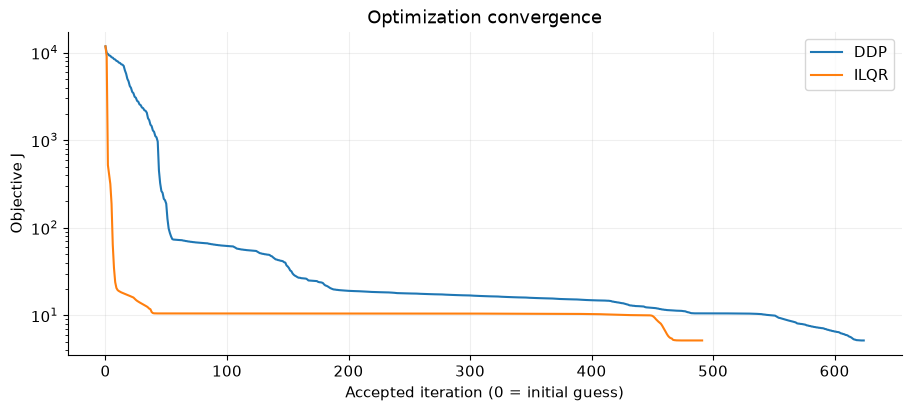

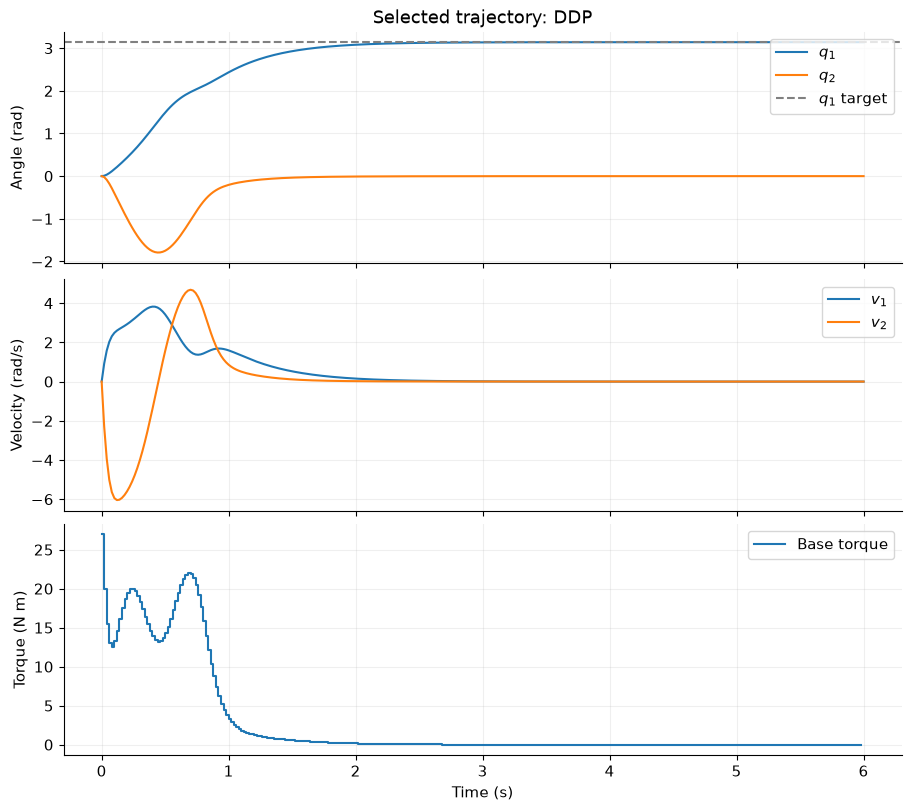

In [21]:
fig, ax = plt.subplots(layout="constrained")
for method, result in results.items():
    ax.semilogy(np.arange(len(result["costs"])), result["costs"], label=method.upper())
ax.set(xlabel="Accepted iteration (0 = initial guess)", ylabel="Objective J", title="Optimization convergence")
ax.legend()
plt.show()

best = min(results.values(), key=lambda result: result["cost"])
t = np.arange(cfg.n+1)*cfg.dt
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True, layout="constrained")
axes[0].plot(t, best["x"][:, :2], label=[r"$q_1$", r"$q_2$"])
axes[0].axhline(np.pi, color="gray", ls="--", label=r"$q_1$ target")
axes[0].set(ylabel="Angle (rad)", title=f"Selected trajectory: {best['method'].upper()}")
axes[1].plot(t, best["x"][:, 2:], label=[r"$v_1$", r"$v_2$"])
axes[1].set(ylabel="Velocity (rad/s)")
axes[2].step(t[:-1], best["u"][:, 0], where="post", label="Base torque")
axes[2].set(xlabel="Time (s)", ylabel="Torque (N m)")
for ax in axes:
    ax.legend(loc="upper right")
plt.show()

## 16. Trajectory feedback and upright LQR

Open-loop execution replays $\bar u_k$. Trajectory feedback instead uses
$$u_k=\bar u_k-K_k(x_k-\bar x_k).$$
At $T$, switch both experiments to a local upright LQR. Linearize the **discrete**
map at $(x_\star,0)$ to obtain $A_\star,B_\star$, then solve
$$P=Q_L+A_\star^TPA_\star-A_\star^TPB_\star
(R_L+B_\star^TPB_\star)^{-1}B_\star^TPA_\star,$$
$$K_L=(R_L+B_\star^TPB_\star)^{-1}B_\star^TPA_\star,\qquad
u=-K_L(x-x_\star).$$
Use $Q_L=\Delta t\operatorname{diag}(100,100,10,10)$ and $R_L=0.1\Delta t$.
Eigenvalues of $A_\star-B_\star K_L$ inside the unit circle indicate local
linear stability; this does not guarantee capture from arbitrary states.

For execution, integrate with ten smaller RK4 substeps while updating control
once per $\Delta t$. Compare nominal execution and an initial angle offset
$[0.03,-0.02]$ rad. Finite simulation and arrival/hold errors are reported explicitly.
Even the nominal open-loop run has a small model mismatch because execution uses
finer integration than planning; instability can amplify that difference. A trace
ends if the simulation becomes nonfinite or exceeds the numerical stopping threshold.

In [22]:
def upright_lqr(cfg):
    z = jnp.concatenate((GOAL, jnp.zeros(1)))
    Fz = np.asarray(trajectory_jacobians(z[None], cfg)[0])
    A, B = Fz[:, :4], Fz[:, 4:]
    QL, RL = cfg.dt*np.diag([100., 100., 10., 10.]), cfg.dt*np.array([[.1]])
    P = solve_discrete_are(A, B, QL, RL)
    K = np.linalg.solve(RL+B.T@P@B, B.T@P@A)
    radius = np.max(np.abs(np.linalg.eigvals(A-B@K)))
    return K, radius

@partial(jax.jit, static_argnames=("cfg",))
def fine_step(x, u, cfg):
    return jax.lax.fori_loop(0, 10, lambda _, state: rk4(state, u, cfg.dt/10, cfg), x)

def execute(nominal, K_lqr, cfg, feedback=True, offset=None, hold_seconds=5.0):
    x = np.asarray(X0).copy()
    if offset is not None:
        x += np.asarray(offset)
    total_steps = cfg.n+round(hold_seconds/cfg.dt)
    xs, us, terminated_at = [x.copy()], [], None
    for k in range(total_steps):
        if k < cfg.n:
            u = nominal["u"][k].copy()
            if feedback:
                u -= nominal["gains"][k]@(x-nominal["x"][k])
        else:
            u = -K_lqr@(x-np.asarray(GOAL))
        x = np.asarray(fine_step(jnp.asarray(x), jnp.asarray(u), cfg)).copy()
        xs.append(x.copy())
        us.append(float(u[0]))
        if not np.all(np.isfinite(x)) or np.max(np.abs(x)) > 1e5:
            terminated_at = (k+1)*cfg.dt
            missing = total_steps-len(us)
            xs.extend([np.full(4, np.nan)]*missing)
            us.extend([np.nan]*missing)
            break
    return {"x": np.asarray(xs), "u": np.asarray(us), "terminated_at": terminated_at}

K_lqr, spectral_radius = upright_lqr(cfg)
print("Upright LQR gain:", K_lqr)
print("Closed-loop spectral radius:", spectral_radius)
assert spectral_radius < 1

runs = {}
metrics = []
for case, offset in [("nominal", None), ("initial offset", [0.03, -0.02, 0., 0.])]:
    for feedback in (False, True):
        label = f"{case}: {'trajectory feedback' if feedback else 'open loop'} + LQR"
        run = execute(best, K_lqr, cfg, feedback, offset)
        runs[label] = run
        error = physical_error(run["x"])
        finite = run["terminated_at"] is None
        arrival_finite = bool(np.all(np.isfinite(error[cfg.n])))
        arrival_a = float(np.max(np.abs(error[cfg.n, :2]))) if arrival_finite else np.nan
        arrival_v = float(np.max(np.abs(error[cfg.n, 2:]))) if arrival_finite else np.nan
        hold_a = float(np.max(np.abs(error[cfg.n:, :2]))) if finite else np.nan
        hold_v = float(np.max(np.abs(error[cfg.n:, 2:]))) if finite else np.nan
        metrics.append({"experiment": label, "completed": finite,
                        "stopped at (s)": run["terminated_at"] if not finite else "—",
                        "arrival angle (rad)": arrival_a, "arrival speed (rad/s)": arrival_v,
                        "hold angle (rad)": hold_a, "hold speed (rad/s)": hold_v,
                        "arrival pass": arrival_finite and arrival_a < .05 and arrival_v < .10,
                        "hold pass": finite and hold_a < .10 and hold_v < .25})
show_table(metrics)

Upright LQR gain: [[-146.04861639 -133.43716193  -61.58416774  -33.07725482]]
Closed-loop spectral radius: 0.9465512807854233


| experiment | completed | stopped at (s) | arrival angle (rad) | arrival speed (rad/s) | hold angle (rad) | hold speed (rad/s) | arrival pass | hold pass |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| nominal: open loop + LQR | False | 6.14 | 2.39316 | 9.65298 | nan | nan | False | False |
| nominal: trajectory feedback + LQR | True | — | 4.09448e-08 | 1.65714e-07 | 6.57964e-08 | 2.86833e-07 | True | True |
| initial offset: open loop + LQR | False | 6.16 | 1.93245 | 11.6759 | nan | nan | False | False |
| initial offset: trajectory feedback + LQR | True | — | 4.00555e-08 | 1.62082e-07 | 6.43335e-08 | 2.80492e-07 | True | True |

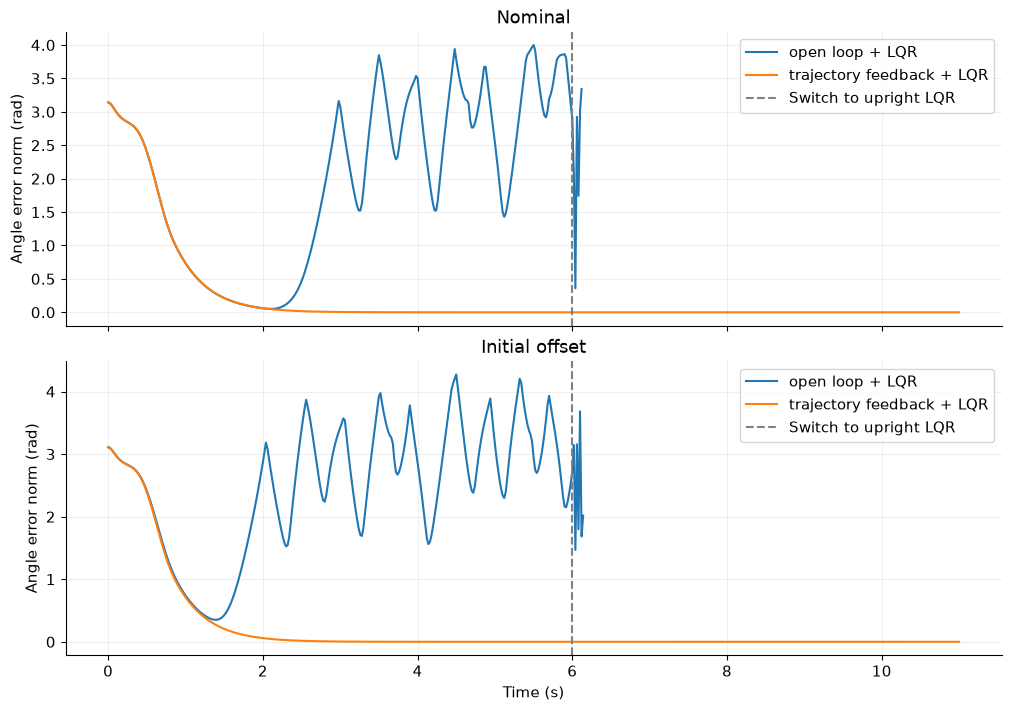

In [23]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True, layout="constrained")
for ax, case in zip(axes, ("nominal", "initial offset")):
    for label, run in runs.items():
        if label.startswith(case+":"):
            angle_error = np.linalg.norm(physical_error(run["x"])[:, :2], axis=1)
            ax.plot(np.arange(len(angle_error))*cfg.dt, angle_error, label=label.split(": ")[1])
    ax.axvline(cfg.duration, color="gray", ls="--", label="Switch to upright LQR")
    ax.set(ylabel="Angle error norm (rad)", title=case.capitalize())
    ax.legend()
axes[-1].set(xlabel="Time (s)")
plt.show()

## 17. Animate the robot inside the notebook

This inline animation uses the computed nominal feedback run. The base remains
fixed; only the first joint is driven. No web server, dashboard, or video encoder
is used. The animation is embedded as JavaScript/HTML by Matplotlib.

In [24]:
animation_run = runs["nominal: trajectory feedback + LQR"]
stride = max(1, round(0.10/cfg.dt))
frame_indices = list(range(0, len(animation_run["x"]), stride))
if frame_indices[-1] != len(animation_run["x"])-1:
    frame_indices.append(len(animation_run["x"])-1)
fig, ax = plt.subplots(figsize=(5, 5))
reach = 1.15*(cfg.l1+cfg.l2)
ax.set(xlim=(-reach, reach), ylim=(-reach, reach), aspect="equal",
       xlabel="Horizontal position (m)", ylabel="Vertical position (m)")
line1, = ax.plot([], [], "o-", lw=5, color="#087e8b")
line2, = ax.plot([], [], "o-", lw=5, color="#d88936")
ax.plot(0, 0, "ks", ms=9)
title = ax.set_title("")
def update_animation(frame):
    k = frame_indices[frame]
    points = joint_positions(animation_run["x"][k], cfg)
    line1.set_data(points[:2, 0], points[:2, 1])
    line2.set_data(points[1:, 0], points[1:, 1])
    phase = "Trajectory feedback" if k < cfg.n else "Upright LQR"
    title.set_text(f"{phase} | t = {k*cfg.dt:.2f} s")
    return line1, line2, title

animation = FuncAnimation(fig, update_animation, frames=len(frame_indices),
                          interval=1000*stride*cfg.dt, blit=False)
animation_html = animation.to_jshtml()
plt.close(fig)
display(HTML(animation_html))

## 18. Experiments and interpretation

Change one setting at a time in Section 2, then rerun from there:

| Change | What to inspect |
|---|---|
| `cfg = replace(cfg, r=0.05)` | Torque penalty, peak effort, and terminal error |
| `cfg = replace(cfg, duration=8.0)` | More planning time, changed trajectory and convergence |
| `cfg = replace(cfg, m2=1.5)` | Inertia, gravity, and torque required to move the passive link |
| `cfg = replace(cfg, dt=0.01)` | Finer numerical model, larger optimization problem |
| `initial_u = jnp.zeros((cfg.n, 1))` in Section 8 | Sensitivity to the initial torque guess |

Keep weights as tuples and timing as an integer number of intervals. Very large
steps or extreme parameters may make RK4 inaccurate or prevent optimization.
Inspect status and measured errors before interpreting a trajectory as successful.

**What to remember:** Euler–Lagrange supplies the mechanical equations; RK4 creates
the discrete model; Bellman's principle supplies the local Hamiltonian; the backward
pass produces torque corrections and gains; nonlinear forward search accepts a
decreasing-cost trajectory. Full DDP includes dynamics curvature, while iLQR drops it.
Trajectory feedback tracks swing-up and a separate local LQR holds upright.

This notebook adapts the dynamics and numerical method from the companion
`nurchoolsm2-hub/Pendubot_Opt_Control` project into visible, standalone teaching code.
Its outputs are computed here rather than loaded from that repository.